# Neuro4ML Coursework

Below, each question that needs a response will be marked by a ⚠️.

In this coursework, you will use a data set of spike trains recorded from monkey motor cortex while it was doing a task involving moving a pointer on a screen. The aim of this coursework is to decode the recorded velocity of the pointer from the neural data using a network of leaky integrate-and-fire neurons that take the recorded spikes as input and give sequences of velocities as outputs. You will train these networks using surrogate gradient descent. If you haven't already looked at it, a great starting point is Friedemann Zenke's [SPyTorch tutorial notebook 1](https://github.com/fzenke/spytorch/blob/main/notebooks/SpyTorchTutorial1.ipynb) (and the rest are worth looking at too).

In this coursework, we are following the general approach of the article ["Machine learning for neural decoding" (Glaser et al. 2020)](https://doi.org/10.1523/ENEURO.0506-19.2020), but using a spiking neural network decoder instead of the statistical and artificial neural network models used in that paper. You can also have a look at the [GitHub repository for the paper](https://github.com/KordingLab/Neural_Decoding). In case you're interested, the data were originally recorded for the paper ["Population coding of conditional probability distributions in dorsal premotor cortex" (Glaser et al. 2018)](https://doi.org/10.1038/s41467-018-04062-6), but you do not need to read this paper to understand this coursework.

The general setup is illustrated in this figure:

![Cartoon of decoder setup](cartoon.png)

You are given an array of ``num_neurons`` spike trains in a variable ``spike_trains``. This variable is a Python list of numpy arrays, each numpy array has a different length and is the recorded times (in seconds) that the corresponding neuron fired a spike. You also have two additional arrays ``vel`` and ``vel_times`` where ``vel`` has shape ``(num_time_points, 2)`` and ``vel_times`` has has shape ``(num_time_points)``. The second axis of ``vel`` has length 2 corresponding to the x and y-components of the recorded velocity.

## Setting up

This section has some basics to get you started.

Let's start by importing some libraries you can make use of. You can solve all the task only using the imports below, but you are welcome to add your own.

In [1]:
import pickle

import numpy as np
from scipy import io
from scipy.signal import savgol_filter
# !pip install matplotlib
import matplotlib.pyplot as plt

import torch
from torch import nn
import torch.nn.functional as tnnf
mse = nn.MSELoss()

from tqdm.notebook import tqdm

ms = 1e-3 # use this constant so you can write e.g. 1*ms for a time

You already have a copy of the raw data, but for your information, here is where the original can be downloaded.

In [2]:
import urllib.request, zipfile, os
filename = 's1_data_raw.mat'
if not os.path.exists(filename):
    urllib.request.urlretrieve('https://www.dropbox.com/sh/n4924ipcfjqc0t6/AACPWjxDKPEzQiXKUUFriFkJa?dl=1', 'data.zip')
    with zipfile.ZipFile('data.zip') as z:
        z.extract(filename)

## Task 1: Load and plot the data

The code below first loads the raw data, which is stored as a Matlab file, and then extracts the three arrays ``spike_times``, ``vel`` and ``vel_times``.

In [3]:
# Load the raw data
data = io.loadmat('s1_data_raw.mat') # a matlab file!
# print(type(data))
print(data.keys())
print(type(data["spike_times"]), len(data["spike_times"]))
print(type(data["vels"]), data["vels"].shape)
print(type(data["vel_times"]), data["vel_times"].shape)
spike_times = [st[:, 0] for st in data['spike_times'].ravel()] # a list of arrays of spike times in seconds, one for each neuron, spike times in seconds
vel = data['vels'] # velocity data shape (num_time_points, 2) for (x, y) coordinates
vel_times = data['vel_times'].squeeze() # times the velocities were recorded

dict_keys(['__header__', '__version__', '__globals__', 'spike_times', 'vel_times', 'pos', 'acc', 'vels'])
<class 'numpy.ndarray'> 52
<class 'numpy.ndarray'> (306700, 2)
<class 'numpy.ndarray'> (306700, 1)


### Task 1A: Preprocess and compute basic statistics

In this task, you will preprocess the data, extract some basic statistics from it.

1. ⚠️ Whiten the recorded velocities (i.e. transform them so that their mean is 0 and standard deviation is 1).
2. ⚠️ Compute and print out the number of neurons and number of spikes recorded.
3. ⚠️ Compute and print out the duration of the experiment in seconds and/or minutes.
4. ⚠️ Compute and print out the sampling rate at which spikes were recorded (or find the information in the corresponding paper).
5. ⚠️ Compute and print out the sampling rate at which velocities were recorded (or find the information in the corresponding paper).

Note that the spikes and velocities were recorded with different equipment and so they have different sampling rates. Think about how you can estimate these sampling rates from the recorded data (or look it up in the paper).

[[5.83248543e-03 5.77028850e-03]
 [2.56224185e-02 2.73502460e-02]
 [3.40173946e-02 3.98088043e-02]
 ...
 [8.71753651e-05 1.86206186e-04]
 [8.83956715e-05 1.85963547e-04]
 [9.02475738e-05 1.87070724e-04]]
Mean = 1.7838862293292373e-18
Std = 1.0
Neuron and Spike Count:
Number of neurons: 52
Number of spikes:  1480032 

Time Count:
Duration: 3071.3243333333335s = 51.18873888888889min 
(velocities from 1.17 s to 3068.16 s) 

Spike Sample Rate:
Spike sampling rate: 30000.00 Hz (period 33.33us) 

Vel Sample Rate:
Velocity sampling rate: 100.00 Hz (period 10.00ms) 

Spikes go from 0.0094 s to 3071.3337333333334 s
Velocities go from 1.17 s to 3068.16 s
Number of spikes before the velocity starts: 430
Number of spikes after the velocity ends: 1134


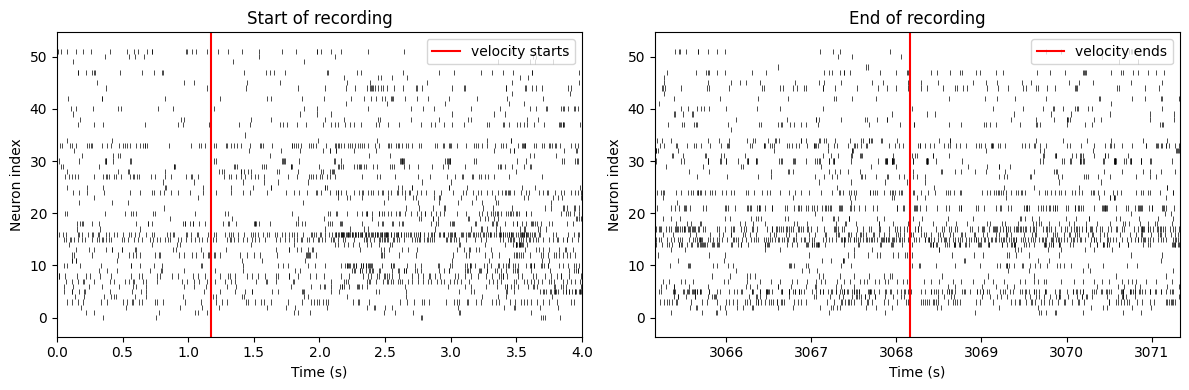

In [4]:
v_t = data['vel_times']
v = data['vels']
# print(v.shape)
# print(v_t[0])

# transform
mean = np.mean(v, axis=0)
std = np.std(v, axis=0)
v_normalised = (v - mean) / std
print(v_normalised)
print(f"Mean = {np.mean(v_normalised)}")
print(f"Std = {np.std(v_normalised)}")

# number of neurons and spikes
num_neurons = len(spike_times)
num_spikes = sum(len(st) for st in spike_times)
print("Neuron and Spike Count:")
print(f"Number of neurons: {num_neurons}")
print(f"Number of spikes:  {num_spikes} \n")


# time
t_first = min(min(st.min() for st in spike_times), vel_times.min())
t_last = max(max(st.max() for st in spike_times), vel_times.max())
duration = t_last - t_first
print("Time Count:")
print(f"Duration: {duration}s = {duration/60}min \n(velocities from {vel_times[0]} s to {vel_times[-1]} s) \n")

# sampling rate of spikes
print("Spike Sample Rate:")
all_spikes_sorted = np.sort(np.concatenate(spike_times)) # recall that times go between 0 and 3071.3stg
isi_all = np.diff(all_spikes_sorted)
spike_dt = isi_all[isi_all > 0].min()
spike_fs = 1 / spike_dt
# Check: all spike times should be (close to) integer multiples of this period
print(f"Spike sampling rate: {spike_fs:.2f} Hz (period {spike_dt*1e6:.2f}us) \n")


# sampling rate of velocity
print("Vel Sample Rate:")
vel_dt = np.median(np.diff(vel_times))
print(f"Velocity sampling rate: {1/vel_dt:.2f} Hz (period {vel_dt*1e3:.2f}ms) \n")

# comaring the range of times for spiking data vs the velocities
spike_start = all_spikes_sorted[0]
spike_end = all_spikes_sorted[-1]
vel_start = vel_times[0]
vel_end = vel_times[-1]

print("Spikes go from", spike_start, "s to", spike_end, "s")
print("Velocities go from", vel_start, "s to", vel_end, "s")
print("Number of spikes before the velocity starts:", np.sum(all_spikes_sorted < vel_start))
print("Number of spikes after the velocity ends:", np.sum(all_spikes_sorted > vel_end))

plt.figure(figsize=(12, 4))

# zoom into the start of the recording
start_spikes = [st[st < 4] for st in spike_times]
plt.subplot(1, 2, 1)
plt.eventplot(start_spikes, colors='k', linewidths=0.5)
plt.axvline(vel_start, color='r', label='velocity starts')
plt.xlim(0, 4)
plt.xlabel('Time (s)')
plt.ylabel('Neuron index')
plt.title('Start of recording')
plt.legend()

# zoom into the end of the recording
end_spikes = [st[st > vel_end - 3] for st in spike_times]
plt.subplot(1, 2, 2)
plt.eventplot(end_spikes, colors='k', linewidths=0.5)
plt.axvline(vel_end, color='r', label='velocity ends')
plt.xlim(vel_end - 3, spike_end)
plt.xlabel('Time (s)')
plt.ylabel('Neuron index')
plt.title('End of recording')
plt.legend()

plt.tight_layout()
plt.show()

### Task 1B: Plot the data

In this task, you will plot the data to get a feeling for what it is like (an important step in any modelling).

1. ⚠️ Plot the spike times as a raster plot (black dots at x-coordinates the time of the spike, and y-coordinates the index of the neuron). Plot this both for the whole data set and for the period from 1000 to 1010 seconds.
2. ⚠️ Plot the x- and y-coordinates of the velocities. Plot this both for the whole data set and for the same period as above for the spikes.
3. ⚠️ Compute the mean firing rate (number of spikes per second) for each neuron and display as a bar chart.
4. ⚠️ Plot the velocities as a curve in (x, y) space, emphasising the part of the velocity curve for the period above.

You can use the template below to get you started.

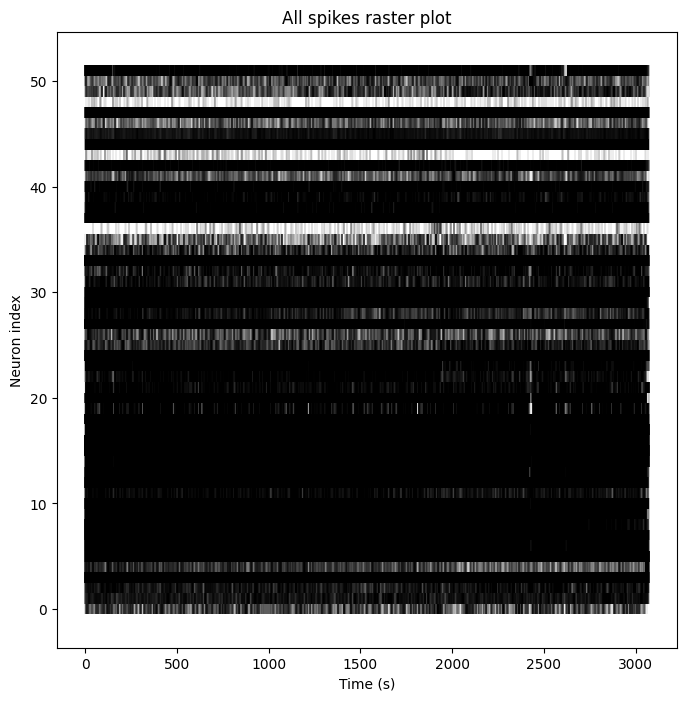

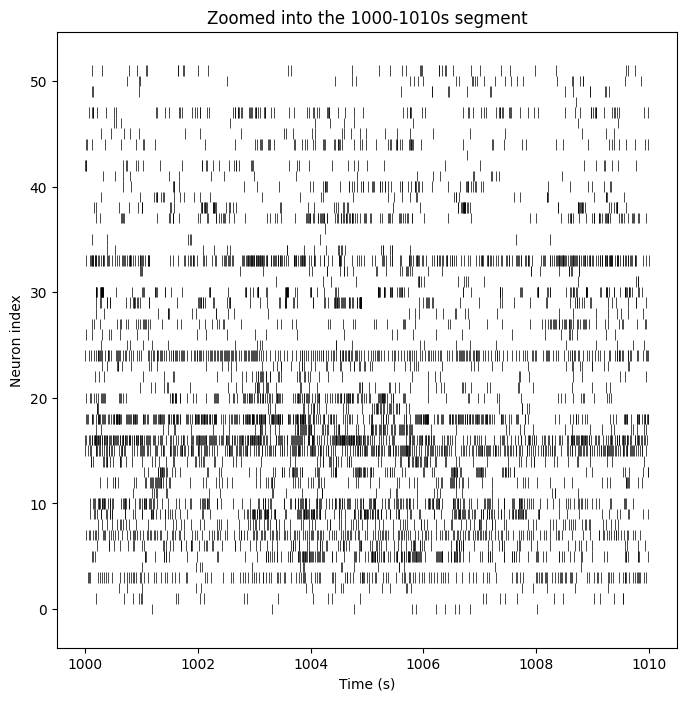

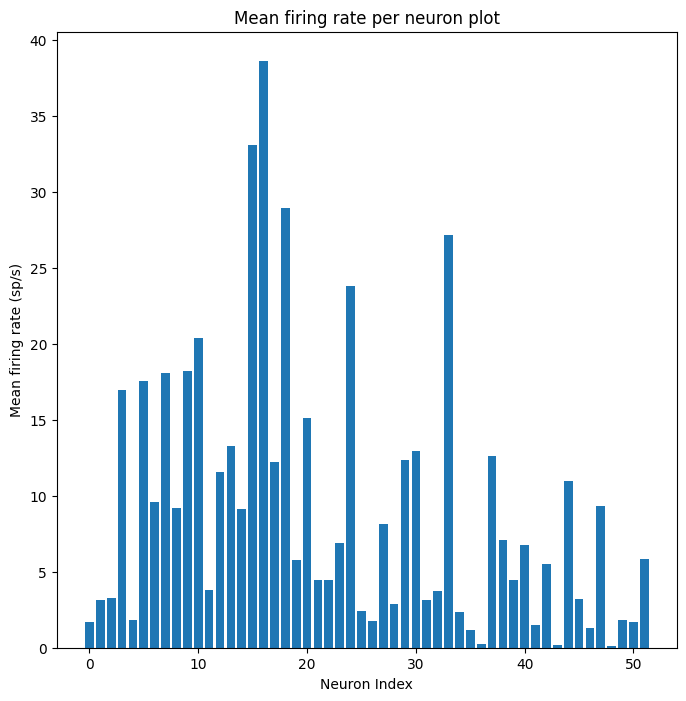

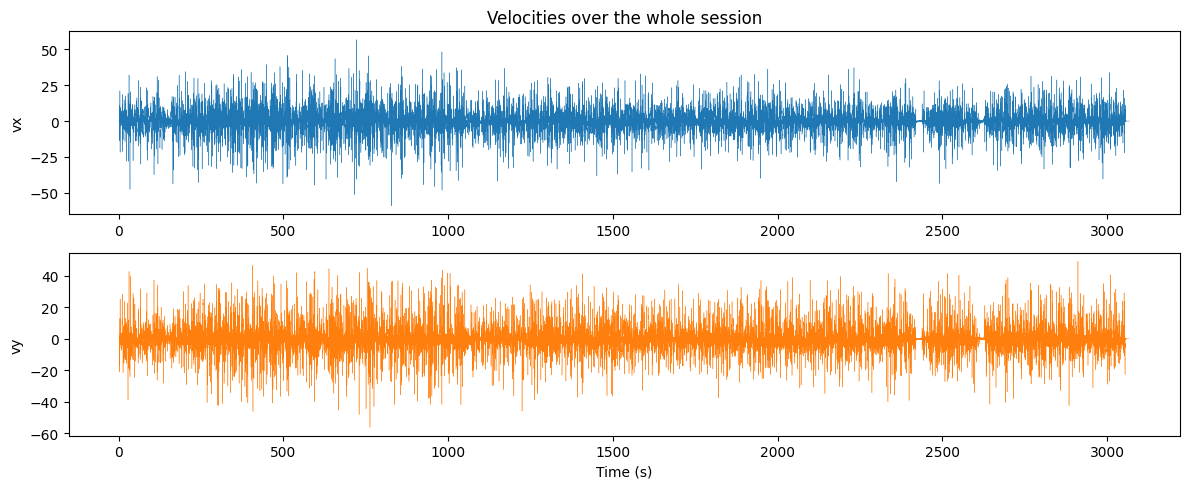

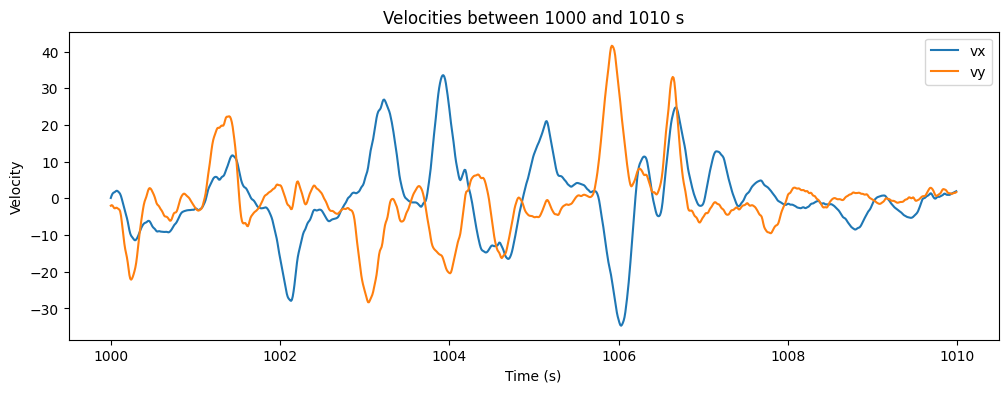

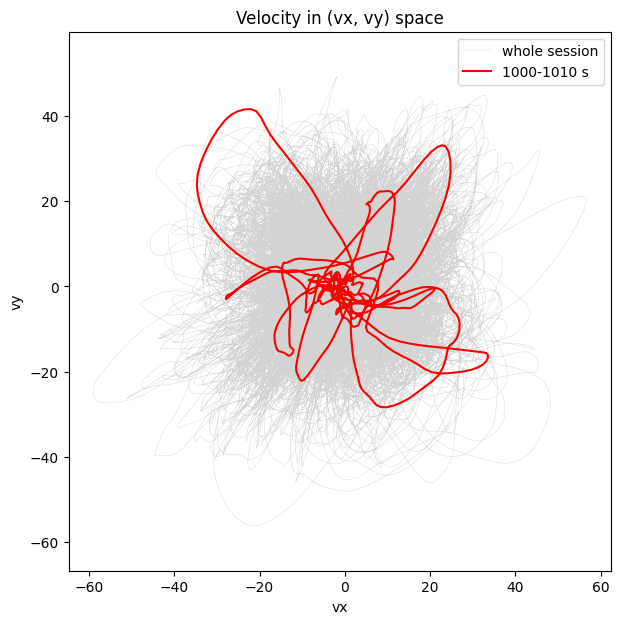

In [5]:
# raster plot
plt.figure(figsize=(8, 8))
plt.eventplot(spike_times, colors='k', linewidths=0.1)   # row i = spike_times[i]
plt.xlabel('Time (s)')
plt.ylabel('Neuron index')
plt.title('All spikes raster plot')
plt.show()

# rater of the smaller interval between 1000 and 1010s
t0, t1 = 1000, 1010 
zoomed = [ st[(st >= t0) & (st < t1)] for st in spike_times ] # slice out the rasters from between this range
plt.figure(figsize=(8, 8))
plt.eventplot(zoomed, colors='k', linewidths=0.5)
plt.xlabel('Time (s)')
plt.ylabel('Neuron index')
plt.title('Zoomed into the 1000-1010s segment')
plt.show()

# mean firing rate per neuron
means = np.array([len(st) for st in spike_times]) /  duration
plt.figure(figsize=(8, 8))
plt.bar(np.arange(len(means)), means)
plt.xlabel('Neuron Index')
plt.ylabel('Mean firing rate (sp/s)')
plt.title('Mean firing rate per neuron plot')
plt.show()


# x and y velocities over the whole session
plt.figure(figsize=(12, 5))
plt.subplot(2, 1, 1)
plt.plot(vel_times, vel[:, 0], lw=0.3)
plt.ylabel('vx')
plt.title('Velocities over the whole session')
plt.subplot(2, 1, 2)
plt.plot(vel_times, vel[:, 1], lw=0.3, color='C1')
plt.ylabel('vy')
plt.xlabel('Time (s)')
plt.tight_layout()
plt.show()

# x and y velocities between 1000 and 1010 s
t0, t1 = 1000, 1010
in_window = (vel_times >= t0) & (vel_times < t1)
plt.figure(figsize=(12, 4))
plt.plot(vel_times[in_window], vel[in_window, 0], label='vx')
plt.plot(vel_times[in_window], vel[in_window, 1], label='vy')
plt.xlabel('Time (s)')
plt.ylabel('Velocity')
plt.title('Velocities between 1000 and 1010 s')
plt.legend()
plt.show()

# velocity as a curve in (vx, vy) space, highlighting 1000-1010 s
plt.figure(figsize=(7, 7))
plt.plot(vel[:, 0], vel[:, 1], color='lightgrey', lw=0.3, label='whole session')
plt.plot(vel[in_window, 0], vel[in_window, 1], color='r', lw=1.5, label='1000-1010 s')
plt.xlabel('vx')
plt.ylabel('vy')
plt.title('Velocity in (vx, vy) space')
plt.axis('equal')
plt.legend()
plt.show()


## Task 2: Divide data into test/train and batches

In this section, you will divide the data up into non-overlapping test, train and (optionally) validation sets.

### Task 2A: Why not just use continuous time ranges?

In the Glaser et al. paper linked to above, they simply divide the range so that the first 70% of the data is used for training, the next 15% for validation and the last 15% for testing. This is a standard thing to do.

1. ⚠️ Compute the speeds from the velocity components, plot them and compute some statistics to show why this is a bad idea for this dataset. To make the plot clear, you might want to take averages over some window rather than plotting every point.

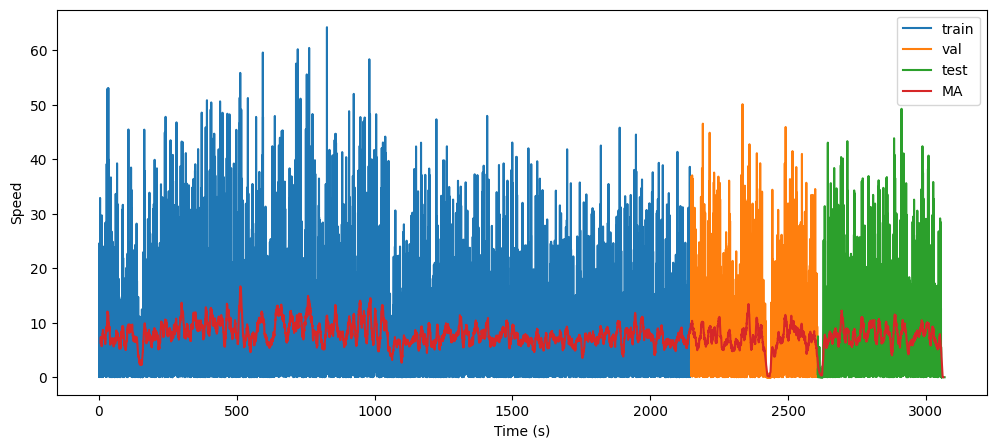

train  mean=7.98  median=5.45  
std=7.80  stationary=9.17%
val  mean=7.13  median=5.01  
std=7.04  stationary=13.47%
test  mean=7.32  median=5.14  
std=7.05  stationary=13.15%


In [6]:
# v.shape()[0] samples
train_index, val_index = 0.7 * v.shape[0], 0.85 * v.shape[0]


speed = np.sqrt(vel[:, 0]**2 + vel[:, 1]**2)
# print(speed, speed.shape)
speed_train = speed[:int(train_index)]
speed_val = speed[int(train_index):int(val_index)]
speed_test = speed[int(val_index):]

n_train = int(train_index)
n_val = int(val_index)

plt.figure(figsize=(12, 5))
plt.plot(vel_times[0:n_train], speed_train, label='train')
plt.plot(vel_times[n_train:n_val], speed_val, label='val')
plt.plot(vel_times[n_val:], speed_test, label='test')

# calc and plot the moving average
window_size = int(10 / (10*ms)) # converting the 10s window we want into # of samples using vel sampling rate=10ms
cumulative = np.cumsum(np.insert(speed, 0, 0))
moving_averages = (cumulative[window_size:] - cumulative[:-window_size]) / window_size
ma_times = vel_times[window_size//2 : window_size//2+len(moving_averages)]

plt.plot(ma_times, moving_averages, label="MA")
plt.legend(loc='best')
plt.xlabel('Time (s)')
plt.ylabel('Speed')
plt.show()


still = 1.0  # any sample with speed below this counts as "stationary"

for name, sp in [('train', speed_train), ('val', speed_val), ('test', speed_test)]:
    print(f"{name}  mean={sp.mean():.2f}  median={np.median(sp):.2f}  ")
    print(f"std={sp.std():.2f}  stationary={100*np.mean(sp < still):.2f}%")


A contiguous 70/15/15 split is a poor choice here because the monkey's behaviour changes over the session. The 10 s moving average of speed shows long pauses near 2400s and 2600s, in the validation and test portions at the end of the data. This means that the training set is more active and smoother (mean speed 7.98, median 5.45, std 7.80) than the validation set (mean 7.13, median 5.01, std 7.04) and the test set (mean 7.32, median 5.14, std 7.05), and the validation/test sets spend more time stationary (speed below 1): 13.47% for validation and 13.15% for test, against 9.17% for training. A decoder trained on the first 70% would therefore be evaluated on less erratic behaviour than it was trained on, so its scores would reflect more of this mismatch rather than on how well it decodes. Interleaving short segments throughout the session avoids this, which is what we do in Task 2B.

### Task 2B: use equally distributed segments for training, test and validation

1. ⚠️ Divide the data up into segments and use some fraction of these segments for training, test and validation, ensuring these segments do not overlap but that they are equally distributed throughout the data.
2. ⚠️ Write a generator function (see below) ``batched_data`` that iterates over your data in randomly ordered segments of a given length, returning it in batches. The function should have arguments that determine the fraction of the data to use, the simulation time step that will be used, the length (in seconds) of each batch, and the batch size (you may add additional arguments if you wish). The function should return a pair of arrays ``(x, y)``. The array ``x`` has shape ``(batch_size, num_neurons, num_time_points)`` containing the spike times as an array where a zero indicates no spike and 1 indicates a spike. Here ``num_time_points`` is the number of time points in the batch measured at the sampling rate of the simulation time step, not the number of time points in the data as a whole, nor at the spike or velocity sampling rate. The array ``y`` has shape ``(batch_size, 2, num_time_points)`` containing the velocities at the same time points as the spikes. You will need to use some sort of interpolation to get the velocities at these times.
3. ⚠️ Plot a sample of spike times and velocities for a random batch of length 1 second and ``batch_size=4``.

#### Note on generator functions

Generator functions are an advanced feature of Python that makes it easy to iterate over complicated datasets. The general syntax is just a standard function that uses the keyword ``yield`` instead of ``return`` to return data, which allows it to return data multiple times. You can iterate over the values returned by a generator function instead of just calling it. Here's an example:

#### Template

You can use the following template but you may want to define some additional helper functions to simplify your code and that you can re-use later.

102 segments of 30 s: 72 train, 
15 val, 15 test


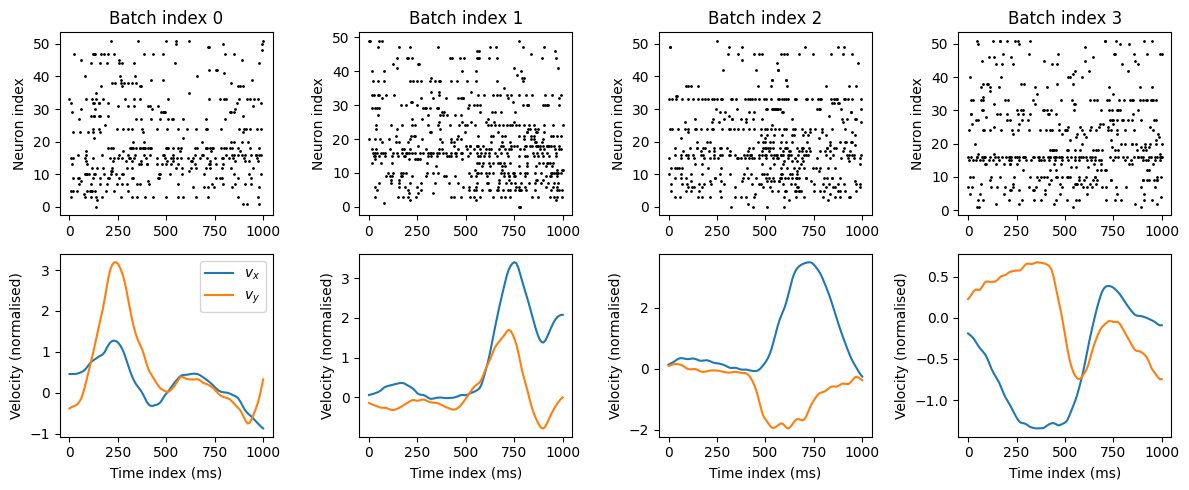

In [7]:
# Split the session into equally distributed, non-overlapping segments 
# Each segment is 30 s long. Segments are labelled train/val/test
# pattern (14 train, 3 val, 3 test = 70/15/15), so every split is spread across the whole session.

seg_len = 30.0  # in s
t_start, t_end = vel_times[0], vel_times[-1]
n_seg = int((t_end - t_start) // seg_len) # dropping the remainder of the data (doesnt fit exactly)
seg_starts = t_start + seg_len * np.arange(n_seg)
segments = np.stack([seg_starts, seg_starts + seg_len], axis=1)  # (n_seg, 2) array of [start, end] times

pattern = np.array(['train'] * 20)
pattern[[4, 11, 17]] = 'val'
pattern[[7, 14, 19]] = 'test'
labels = pattern[np.arange(n_seg) % len(pattern)]

training_range = segments[labels == 'train']
validation_range = segments[labels == 'val']
testing_range = segments[labels == 'test']
print(f"{n_seg} segments of {seg_len:.0f} s: {len(training_range)} train, ")
print(f"{len(validation_range)} val, {len(testing_range)} test")

spike_times = [np.sort(st) for st in spike_times]  # sorted so np.searchsorted can find a window quickly

def batched_data(range_to_use, fraction=1.0, dt=1e-3, length=1, batch_size=64, max_num_batches=None):
    """Yield (x, y) batches of randomly ordered windows taken from the segments in range_to_use.

    x: (batch_size, num_neurons, num_time_points), 1 where a neuron spiked in that dt bin, else 0
    y: (batch_size, 2, num_time_points), normalised (vx, vy) interpolated onto the same dt grid
    """
    num_time_points = int(round(length / dt))
    t_rel = np.arange(num_time_points) * dt
    # Tile every segment into non-overlapping windows of `length` s (a window never crosses a segment edge)
    starts = np.concatenate([np.arange(a, b - length + 1e-9, length) for a, b in range_to_use])
    np.random.shuffle(starts)                         # random order, mixing windows from all segments
    starts = starts[:int(round(fraction * len(starts)))]  # optionally use only part of the data
    num_batches = len(starts) // batch_size
    if max_num_batches is not None:
        num_batches = min(num_batches, max_num_batches)
    for batch_idx in range(num_batches):
        x = torch.zeros((batch_size, num_neurons, num_time_points))
        y = torch.zeros((batch_size, 2, num_time_points))
        for b in range(batch_size):
            t0 = starts[batch_idx * batch_size + b]
            # Spikes -> binary raster at resolution dt
            for n, st in enumerate(spike_times):
                lo, hi = np.searchsorted(st, [t0, t0 + length])
                idx = ((st[lo:hi] - t0) / dt).astype(int)
                x[b, n, idx[idx < num_time_points]] = 1
            # Velocities (sampled every 10 ms) -> linearly interpolated onto the dt grid
            t = t0 + t_rel
            for k in range(2):
                y[b, k] = torch.from_numpy(np.interp(t, vel_times, v_normalised[:, k]))
        yield x, y


x, y = next(batched_data(training_range, dt=1*ms, length=1, batch_size=4))

plt.figure(figsize=(12, 5))
for b in range(4):
    # Plot spikes for this batch index
    ax = plt.subplot(2, 4, b+1)
    neuron_idx, time_idx = np.nonzero(x[b].numpy())
    plt.scatter(time_idx, neuron_idx, s=1, c='k')
    plt.ylabel('Neuron index')
    plt.title(f'Batch index {b}')
    # Plot velocities for this batch index
    plt.subplot(2, 4, b+5, sharex=ax)
    plt.plot(y[b, 0], label='$v_x$')
    plt.plot(y[b, 1], label='$v_y$')
    plt.xlabel('Time index (ms)')
    plt.ylabel('Velocity (normalised)')
    if b == 0:
        plt.legend(loc='best')
plt.tight_layout();

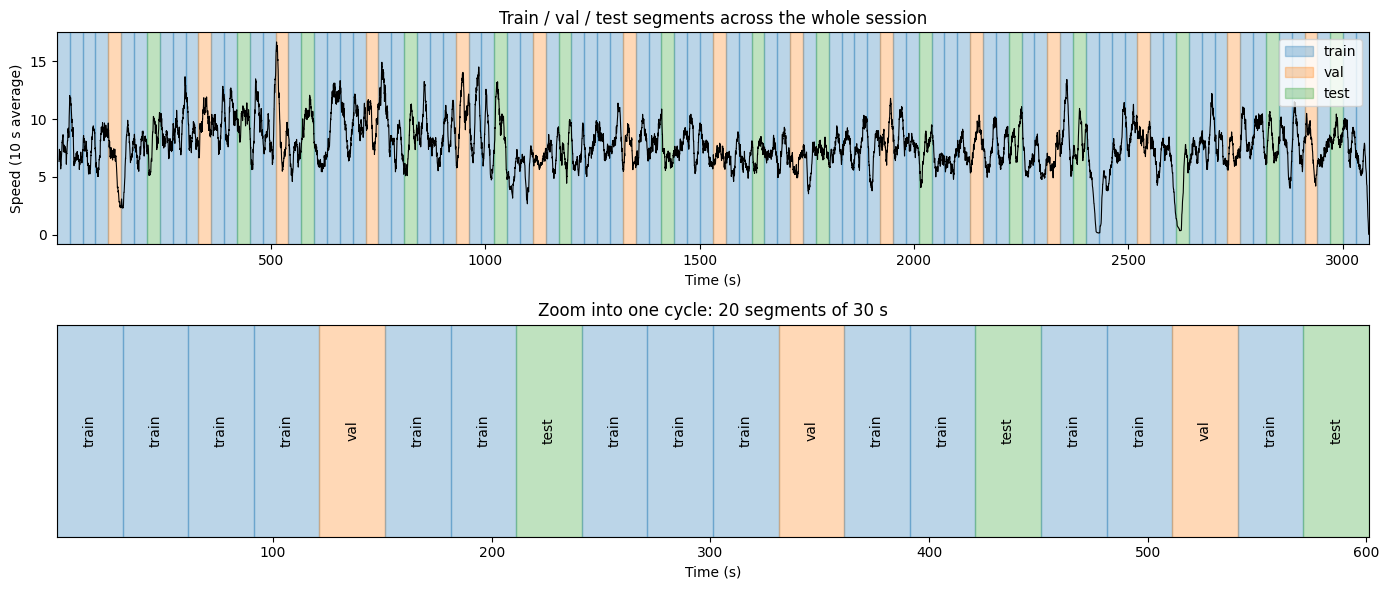

In [8]:
# show which split each segment belongs to, on top of the 10 s moving average of speed from Task 2A
colours = {'train': 'C0', 'val': 'C1', 'test': 'C2'}

plt.figure(figsize=(14, 6))

# whole session
plt.subplot(2, 1, 1)
for (start, end), label in zip(segments, labels):
    plt.axvspan(start, end, color=colours[label], alpha=0.3)
plt.plot(ma_times, moving_averages, 'k', lw=0.8)
for label in colours:
    plt.axvspan(0, 0, color=colours[label], alpha=0.3, label=label)  # empty spans, just for the legend
plt.xlim(segments[0, 0], segments[-1, 1])
plt.xlabel('Time (s)')
plt.ylabel('Speed (10 s average)')
plt.title('Train / val / test segments across the whole session')
plt.legend(loc='upper right')

# zoom into the first cycle of 20 segments
plt.subplot(2, 1, 2)
for i in range(20):
    start, end = segments[i]
    plt.axvspan(start, end, color=colours[labels[i]], alpha=0.3)
    plt.text((start + end) / 2, 0.5, labels[i], ha='center', va='center', rotation=90)
plt.xlim(segments[0, 0], segments[19, 1])
plt.yticks([])
plt.xlabel('Time (s)')
plt.title(f'Zoom into one cycle: 20 segments of {seg_len:.0f} s')

plt.tight_layout()
plt.show()

## Task 3: Spiking neural network model

*   List item
*   List item



In this task, you will write code to simulate a spiking neural network that can be trained using surrogate gradient descent, as in lectures. The neuron model will have some extra features beyond what you have seen in lectures and in the SPyTorch tutorial.

### Surrogate gradient descent spike function

Below is the code for the surrogate gradient descent function from lectures. You can use it as is, although note that there is a hyperparameter (scale) that you can experiment with if you choose.

In [9]:
class SurrogateHeaviside(torch.autograd.Function):
    """
    Here we implement our spiking nonlinearity which also implements
    the surrogate gradient. By subclassing torch.autograd.Function,
    we will be able to use all of PyTorch's autograd functionality.
    Here we use the normalized negative part of a fast sigmoid
    as this was done in Zenke & Ganguli (2018).
    """

    scale = 100.0 # controls steepness of surrogate gradient

    @staticmethod
    def forward(ctx, input):
        """
        In the forward pass we compute a step function of the input Tensor
        and return it. ctx is a context object that we use to stash information which
        we need to later backpropagate our error signals. To achieve this we use the
        ctx.save_for_backward method.
        """
        ctx.save_for_backward(input)
        out = torch.zeros_like(input)
        out[input > 0] = 1.0
        return out

    @staticmethod
    def backward(ctx, grad_output):
        """
        In the backward pass we receive a Tensor we need to compute the
        surrogate gradient of the loss with respect to the input.
        Here we use the normalized negative part of a fast sigmoid
        as this was done in Zenke & Ganguli (2018).
        """
        input, = ctx.saved_tensors
        grad_input = grad_output.clone()
        grad = grad_input/(SurrogateHeaviside.scale*torch.abs(input)+1.0)**2
        return grad

# here we overwrite our naive spike function by the "SurrogateHeaviside" nonlinearity which implements a surrogate gradient
surrogate_heaviside  = SurrogateHeaviside.apply

### Task 3A: Single layer simulation code

1. ⚠️ Write modular code to simulate a layer of leaky integrate-and-fire spiking neurons compatible with autodifferentiation with PyTorch. The new feature compared to what you have seen before is that the time constant parameter $\tau$ should be different for each neuron, and be trainable.

You can write your simulator as a function or class. My recommendation is to derive from the ``nn.Module`` class of PyTorch, but you can do it how you like. The code should accept an input batch of spikes ``x`` of shape ``(batch_size, num_input_neurons, num_time_points)`` and values 0 or 1 (as in the ``batched_data`` generator function above). The code should have the option to produce either spiking or non-spiking output. In both cases, the output should be an array ``y`` of shape ``(batch_size, num_output_neurons, num_time_points)``. In the case of spiking output, the values of ``y`` should be 0s and 1s, and in the case of non-spiking output they should be the membrane potential values. You may also want to write an additional class to handle multiple layers of spiking neural networks for subsequent tasks.

Your code should include initialisation of the weight matrices and time constants, and add additional hyperparameters for this initialisation. I used a spread of time constants from 20-100 ms for spiking neurons and from 200 to 1000 ms for non-spiking neurons and it worked OK, but I didn't do an extensive hyperparameter search and you can probably improve on this.

<!-- I would recommend approaching this and the following sections as follows:

1. Write simulation code for a single layer, non-spiking neural network first. This code is simpler and will train fast (under 3 minutes on Colab). Attempt as much of the remaining tasks as possible using only this.
2. Add the ability for spiking and test that your code produces reasonable output but don't try to train it yet.
3. Add the ability to plot spiking hidden layers and try to get a reasonable initialisation of the network.
4. Start training the spiking neural network. Your final run will probably take a long time to train but you should build up to that by seeing how well the training curves improve for fewer epochs, batch sizes, etc. -->

You can use the template below if you want to use the class-based approach.

You may also find it useful to write a class that chains together a group of layers for later parts of the courseowrk.

In [10]:
class SNNLayer(nn.Module):
  def __init__(self, n_in, n_out, spiking=True, dt=1*ms, threshold=1.0, tau_range=(20*ms, 100*ms), w_normal=(0.0, 0.1)):
    super(SNNLayer, self).__init__()
    self.n_in = n_in
    self.n_out = n_out
    self.spiking = spiking 
    self.dt = dt
    self.threshold = threshold
    self.min_tau = tau_range[0]
    self.max_tau = tau_range[1]
    self.w_mean = w_normal[0]
    self.w_std = w_normal[1]

    # Store weights as a trainable parameter + the time constants per neuron
    self.tau = nn.Parameter(self.min_tau + (self.max_tau - self.min_tau) * torch.rand(n_out)) # we generate random taus for the output time constant randomly between min and max
    self.w = nn.Parameter(self.w_mean + self.w_std * torch.randn(n_in, n_out))
    

  def forward(self, x):
    batch_size, num_neurons, num_time_points = x.shape

    alpha = torch.exp(-self.dt / self.tau) # the ratio of the decay dim is (out,)
    v = torch.zeros(batch_size, self.n_out)
    y = []
    recorded_v = []

    for time in range(num_time_points):
      bias = x[:, :, time] @ self.w # (b, in) @ (in, out)
      v = alpha * v + bias # v is (b, out) and bias is (b, out) - this is one timestep of dt
      recorded_v.append(v) # only for plotting
      
      if self.spiking:
        s = surrogate_heaviside(v - self.threshold) # element wise sub dim is (b, out)
        v = v * (1-s) 
        y.append(s) # spiking layer outputs the 1/0 output not the raw mem pot
      else:
        y.append(v) 

    self.v_record = torch.stack(recorded_v, dim=2).detach()   
    return torch.stack(y, dim=2)

### Task 3B: Verify your code

You will verify your code by simulating a network consisting of:

* One (non-simulated) input neuron firing at a constant rate of 50 sp/s for a total duration of 1 second simulated with a time step of ``dt=1*ms``.
* Two simulated, spiking neurons which each receive spikes from the input neuron with a weight of 0.5. The two simulated neurons should have time constants of 20 ms and 100 ms.

You should:

1. ⚠️ Run the simulation, recording the membrane potentials and spike times of the simulated neurons.
2. ⚠️ Plot the membrane potentials and spike times of the simulated neurons. Print the spike counts of the neurons. The first neuron should not fire any spikes.
3. ⚠️ Write down an analytic solution for the first simulated neuron (that doesn't fire any spikes).
4. ⚠️ Plot your analytic solution on the same graph as the simulated one to show that it is approximately equal.

Spike count, neuron 1 (tau = 20 ms):  0.0
Spike count, neuron 2 (tau = 100 ms):  16.0


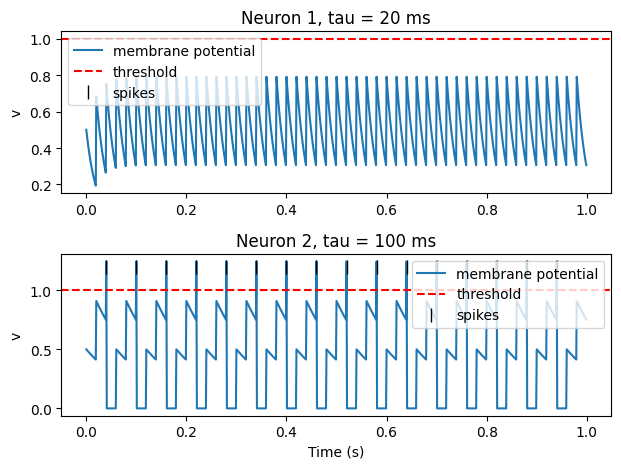

In [11]:
# 50sp/s * 1s. This means 0.02 s/sp (20ms/sp) simulated with dt = 1ms. Leads to 1000 samples (1s/1ms)  
sim_duration = 1
dt = 1*ms
num_samples = int(sim_duration/dt)
input_neuron = torch.zeros(1, 1, num_samples)
step = int(0.02/0.001)
input_neuron[0, 0, ::step]=1
# print(input_neuron.shape)

model = SNNLayer(n_in=1, n_out=2, spiking=True)
with torch.no_grad():
    model.w[:] = 0.5
    model.tau[:] = torch.tensor([20*ms, 100*ms]) 
y = model(input_neuron) # y is (out,) we need to input (b, in, time)
y = y.squeeze()

spikes = y.detach().numpy()
v = model.v_record[0].numpy() 
t = np.arange(num_samples) * dt

print("Spike count, neuron 1 (tau = 20 ms): ", spikes[0].sum())
print("Spike count, neuron 2 (tau = 100 ms): ", spikes[1].sum())

plt.figure()
for i in range(2):
    plt.subplot(2, 1, i+1)
    plt.plot(t, v[i], label='membrane potential')
    plt.axhline(model.threshold, color='r', linestyle='--', label='threshold')
    sim_spike_times = t[spikes[i] == 1]
    plt.plot(sim_spike_times, np.ones(len(sim_spike_times)) * 1.2, 'k|', markersize=10, label='spikes')
    plt.ylabel('v')
    plt.title(f'Neuron {i+1}, tau = {model.tau[i].item()*1000:.0f} ms')
    plt.legend()
plt.xlabel('Time (s)')
plt.tight_layout()
plt.show()

#### Analytic solution for neuron 1 ($\tau_1 = 20ms$)

Neuron 1 never reaches threshold, so it never resets and behaves as a pure leaky integrator. Between input spikes its membrane potential decays,

$\tau \frac{dv}{dt} = -v \quad\Rightarrow\quad v(t) = v(t_0)\, e^{-(t - t_0)/\tau},$

and each input spike at time $t_k = kT$ (with $T = 20ms$ for 50 sp/s) makes $v$ jump up by the weight $w = 0.5$. Adding up the decaying contribution of every input spike so far gives

$v(t) = \sum_{k \,:\, t_k \le t} w\, e^{-(t - t_k)/\tau}.$

For $nT \le t < (n+1)T$, i.e. after $n+1$ input spikes, this is a geometric series:

$$v(t) = w\, e^{-(t - nT)/\tau}\; \frac{1 - e^{-(n+1)T/\tau}}{1 - e^{-T/\tau}}.$$

The peak (just after each input spike) grows towards a steady-state value as $n \to \infty$:

$$v_\text{peak} = \frac{w}{1 - e^{-T/\tau}}.$$

- Neuron 1, $\tau = 20$ ms: $v_\text{peak} = 0.5 / (1 - e^{-1}) \approx 0.79 < 1$, so it never reaches threshold and fires **no spikes**.
- Neuron 2, $\tau = 100$ ms: $v_\text{peak} = 0.5 / (1 - e^{-0.2}) \approx 2.76 > 1$, so it does reach threshold and fires.

The simulation uses $\alpha = e^{-dt/\tau}$, which is the exact decay over one time step, and the input spikes fall exactly on the 1 ms grid. So the simulated values should match the analytic solution at every time step, up to floating-point rounding.

Analytic steady-state peak: 0.7909883534346632
Simulated maximum: 0.7909881
Max difference between simulation and analytic: 4.420853874087527e-07


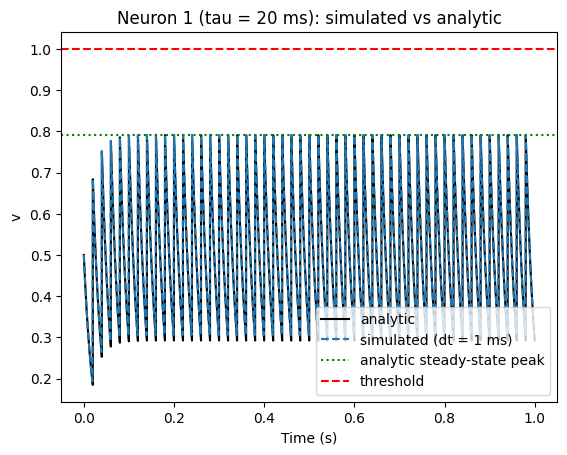

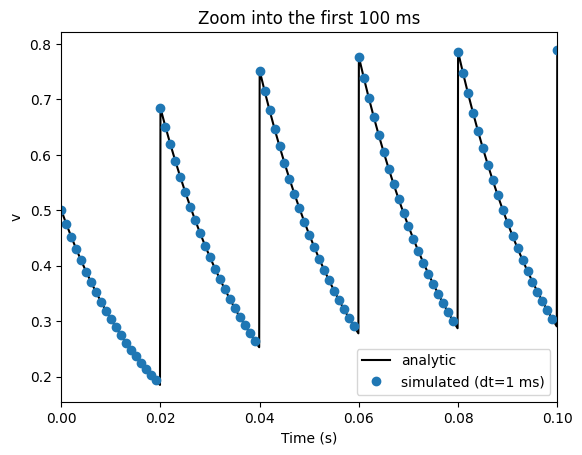

In [12]:
w = 0.5
tau_1 = 20*ms
T_in = 0.02 # input neuron fires every 20 ms (50 sp/s)
input_spike_times = np.arange(0, sim_duration, T_in)

# use a finer time grid so we see the true continuous solution
t_fine = np.arange(0, sim_duration, 0.1*ms)
v_analytic = np.zeros(len(t_fine))
for t_k in input_spike_times:
    # each input spike adds w, which then decays exponentially with time constant tau_1
    v_analytic += w * np.exp(-(t_fine - t_k) / tau_1) * (t_fine >= t_k)

v_peak_steady = w / (1 - np.exp(-T_in / tau_1))   # peak value once the neuron has settled
print("Analytic steady-state peak:", v_peak_steady)
print("Simulated maximum:", v[0].max())

# compare at the simulation time points
v_analytic_on_grid = np.zeros(len(t))
for t_k in input_spike_times:
    v_analytic_on_grid += w * np.exp(-(t - t_k) / tau_1) * (t >= t_k - 1e-9)
print("Max difference between simulation and analytic:", np.abs(v[0] - v_analytic_on_grid).max())

plt.figure()
plt.plot(t_fine, v_analytic, 'k', label='analytic')
plt.plot(t, v[0], 'C0--', label='simulated (dt = 1 ms)')
plt.axhline(v_peak_steady, color='g', linestyle=':', label='analytic steady-state peak')
plt.axhline(model.threshold, color='r', linestyle='--', label='threshold')
plt.xlabel('Time (s)')
plt.ylabel('v')
plt.title('Neuron 1 (tau = 20 ms): simulated vs analytic')
plt.legend(loc='lower right')
plt.show()

# zoom into the first 100 ms so the individual jumps and decays are visible
plt.figure()
plt.plot(t_fine, v_analytic, 'k', label='analytic')
plt.plot(t, v[0], 'C0o', label='simulated (dt=1 ms)')
plt.xlim(0, 0.1)
plt.xlabel('Time (s)')
plt.ylabel('v')
plt.title('Zoom into the first 100 ms')
plt.legend(loc='lower right')
plt.show()

## Task 4: Evaluating fit to data

Now that we have our simulation code, we get back to fitting this model to data.

1. ⚠️ Write code that takes a network and testing set as input and returns the mean loss over the testing data. The loss is the mean squared error of the output of the network compared to the target data. You may also find it helpful to compute the null loss, which is the loss you would get if you just output all zeros. After training, you should be able to do better than this!
2. ⚠️ Write code that plots some of the internal outputs of the network, for example to show you the spikes produced by hidden layers, calculate their firing rates, etc.
3. ⚠️ Initialise a network with one hidden layer of 100 spiking neurons and one output layer of 2 non-spiking neurons. Run this on a random sample of the data of length 1 and plot the input spikes, hidden layer spikes, output x- and y-velocities, and the data x- and y-velocities. For each spiking layer compute the firing rates of each neuron and plot them as a histogram.

In the next task, you can use this to initialise your networks in a reasonable state. Hidden layers should fire spikes at rates that are not too low and not too high. I aimed for an average firing rate in the range 20-100 and it worked well, but you can experiment with other options. The output layer should give values that are roughly in the right range as the data (i.e. it shouldn't go to +/- 100 if the data is going to only +/- 4). If you look at the spike trains of your hidden layer and all the neurons at initialisation are doing exactly the same thing then it's probably not going to learn very well, so try out some different weight initialisations to see if you can do better.

Print the value of the loss (and optionally the null loss) for your untrained network, to give you an idea of the baseline.

You may want to wrap your evaluation code in a ``with`` statement like below to stop PyTorch from computing gradients when evaluating (unnecessary and expensive):

```python
with torch.no_grad():
    ...
    # whatever you do here won't compute any gradients
```

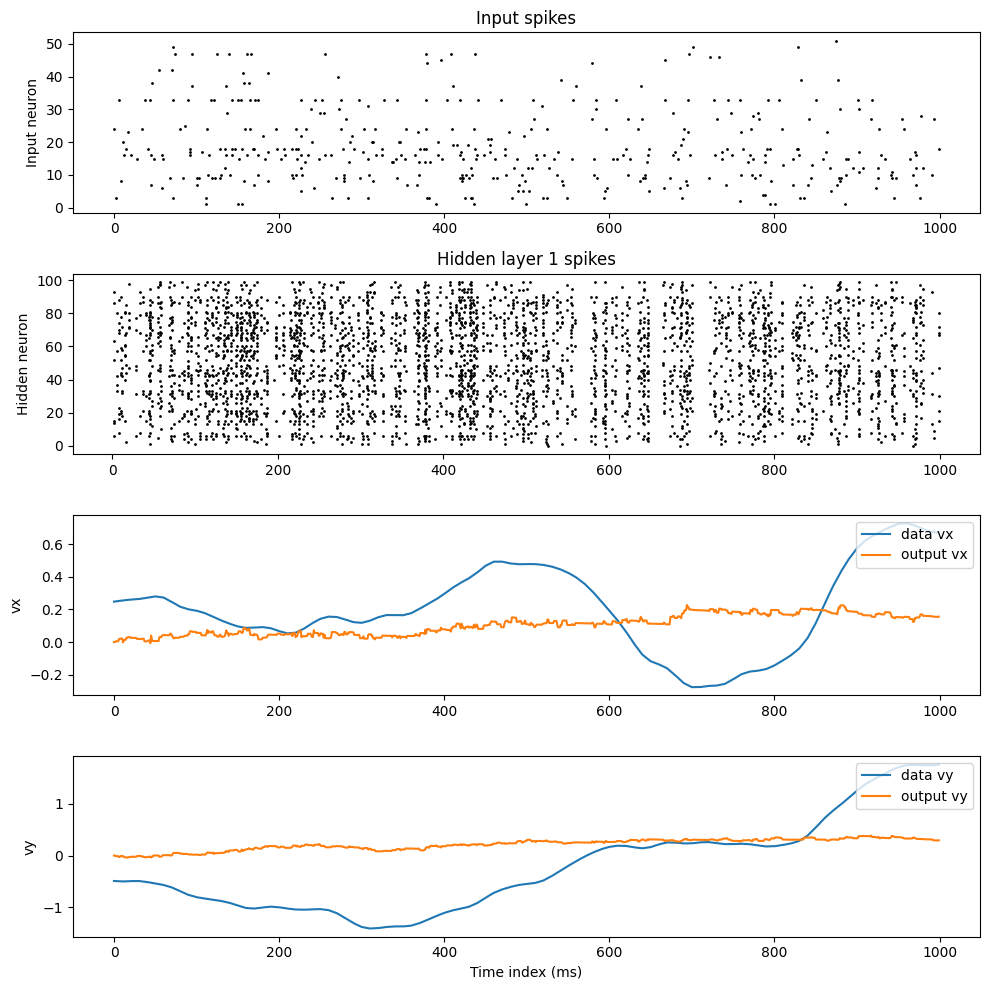

Hidden layer 1: mean rate = 38.9 sp/s, silent neurons = 0/100


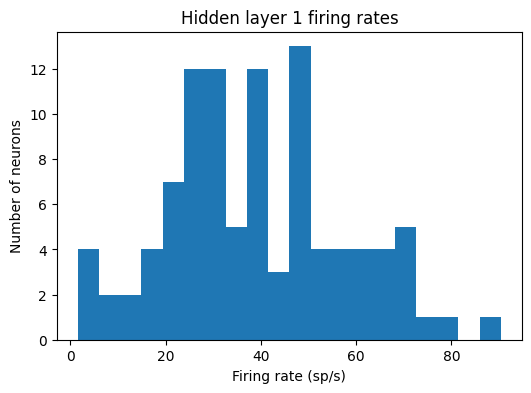

Output range: -0.14 to 0.86 
(data range: -3.35 to 3.44)
Untrained test loss = 1.108, null loss = 1.022


In [13]:
# network class: chains layers together
class SNN(nn.Module):
  def __init__(self, layers, model_name='snn'):
    super(SNN, self).__init__()
    self.layers = nn.ModuleList(layers)
    self.model_name = model_name

  def forward(self, x):
    self.layer_outputs = []
    for layer in self.layers:
      x = layer(x)
      self.layer_outputs.append(x)
    return x # (batch, 2, time) from the non-spiking output layer


# null loss
def evaluate_network(net, range_to_use, dt=1*ms, length=1, batch_size=32, max_num_batches=None):
  losses = []
  null_losses = []
  with torch.no_grad():
    for x, y in batched_data(range_to_use, dt=dt, length=length, batch_size=batch_size, max_num_batches=max_num_batches):
      y_out = net(x) # run the forward pass
      losses.append(mse(y_out, y).item()) # actual loss of the model
      null_losses.append(mse(torch.zeros_like(y), y).item())  #loss if the network just output 0
  return np.mean(losses), np.mean(null_losses)


# internal outputs
def plot_network(net, x, y, b=0, dt=1*ms):
  with torch.no_grad():
    y_out = net(x)
  spiking_layers = [out for layer, out in zip(net.layers, net.layer_outputs) if layer.spiking]
  n_rows = 1 + len(spiking_layers) + 2 # input raster, one raster per spiking layer, vx and vy

  plt.figure(figsize=(10, 2.5 * n_rows))

  # input spikes for sample b
  plt.subplot(n_rows, 1, 1)
  neuron_idx, time_idx = np.nonzero(x[b].numpy())
  plt.scatter(time_idx, neuron_idx, s=1, c='k')
  plt.ylabel('Input neuron')
  plt.title('Input spikes')

  # spikes of each spiking (hidden) layer for sample b
  for i, out in enumerate(spiking_layers):
    plt.subplot(n_rows, 1, i + 2)
    neuron_idx, time_idx = np.nonzero(out[b].numpy())
    plt.scatter(time_idx, neuron_idx, s=1, c='k')
    plt.ylabel('Hidden neuron')
    plt.title(f'Hidden layer {i+1} spikes')

  # network output vs data for vx and vy
  for k, name in enumerate(['vx', 'vy']):
    plt.subplot(n_rows, 1, n_rows - 1 + k)
    plt.plot(y[b, k], label=f'data {name}')
    plt.plot(y_out[b, k], label=f'output {name}')
    plt.ylabel(name)
    plt.legend(loc='upper right')
  plt.xlabel('Time index (ms)')
  plt.tight_layout()
  plt.show()

  # firing rate of every neuron in spiking layers (averaged over the whole batch)
  for i, out in enumerate(spiking_layers):
    rates = out.mean(dim=(0, 2)) / dt # fraction of time steps with a spike / dt = spikes per second
    print(f"Hidden layer {i+1}: mean rate = {rates.mean():.1f} sp/s, silent neurons = {(rates < 1).sum().item()}/{len(rates)}")
    plt.figure(figsize=(6, 4))
    plt.hist(rates.numpy(), bins=20)
    plt.xlabel('Firing rate (sp/s)')
    plt.ylabel('Number of neurons')
    plt.title(f'Hidden layer {i+1} firing rates')
    plt.show()


# initialise a 100-neuron spiking hidden layer + 2 non-spiking outputs
torch.manual_seed(0) # so the initialisation is reproducible
net = SNN([
    SNNLayer(num_neurons, 100, spiking=True, tau_range=(20*ms, 100*ms), w_normal=(0.1, 0.3)),   # ~37 sp/s, no silent neurons
    SNNLayer(100, 2, spiking=False, tau_range=(200*ms, 1000*ms), w_normal=(0.0, 0.005)),  # outputs roughly within +/-2
], model_name='untrained')

x_sample, y_sample = next(batched_data(testing_range, length=1, batch_size=8))
plot_network(net, x_sample, y_sample)
print(f"Output range: {net(x_sample).min().item():.2f} to {net(x_sample).max().item():.2f} ")
print(f"(data range: {y_sample.min().item():.2f} to {y_sample.max().item():.2f})")

# baseline loss of the untrained network
test_loss, null_test_loss = evaluate_network(net, testing_range)
print(f"Untrained test loss = {test_loss:.3f}, null loss = {null_test_loss:.3f}")


## Task 5: Training

At last, we get to the stage of training our network to fit the data.

Start with a network consisting of a single non-spiking output layer (i.e. spikes connected directly via a weight matrix to two non-spiking LIF neurons as output).

1. ⚠️ Find a good initialisation for this network that gives outputs roughly in the right range.
2. ⚠️ Write code to train your network to minimise the mean squared error between the output of your network and the recorded velocities. You will need to select an optimisation algorithm, learning rate, etc.
3. ⚠️ Train your network, plotting the loss curves for the training and validation data during training, and print out the test loss at the end.
4. ⚠️ Plot the output of your model and compare to the data for 8 randomly sampled time windows of length 1.

Don't worry too much about performance at the moment. You should be able to do better than the null loss, but you don't need to do hugely better. I get a null loss of around 1.04 and a test loss of around 0.55, but it's OK if you don't get such good results, and you may get much better results because I didn't do any hyperparameter searching.

You may want to use the following code as a starting point (it worked well enough for me but you can probably do better). On my desktop with CPU only, this took about two minutes to train.

In [14]:
%pip install ipywidgets


Note: you may need to restart the kernel to use updated packages.


  0%|          | 0/400 [00:00<?, ?it/s]

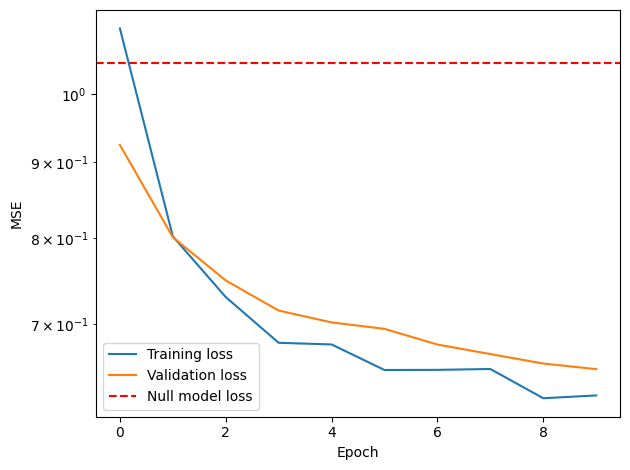

testing_loss=0.6766818250928607, null_testing_loss=1.0284493054662431


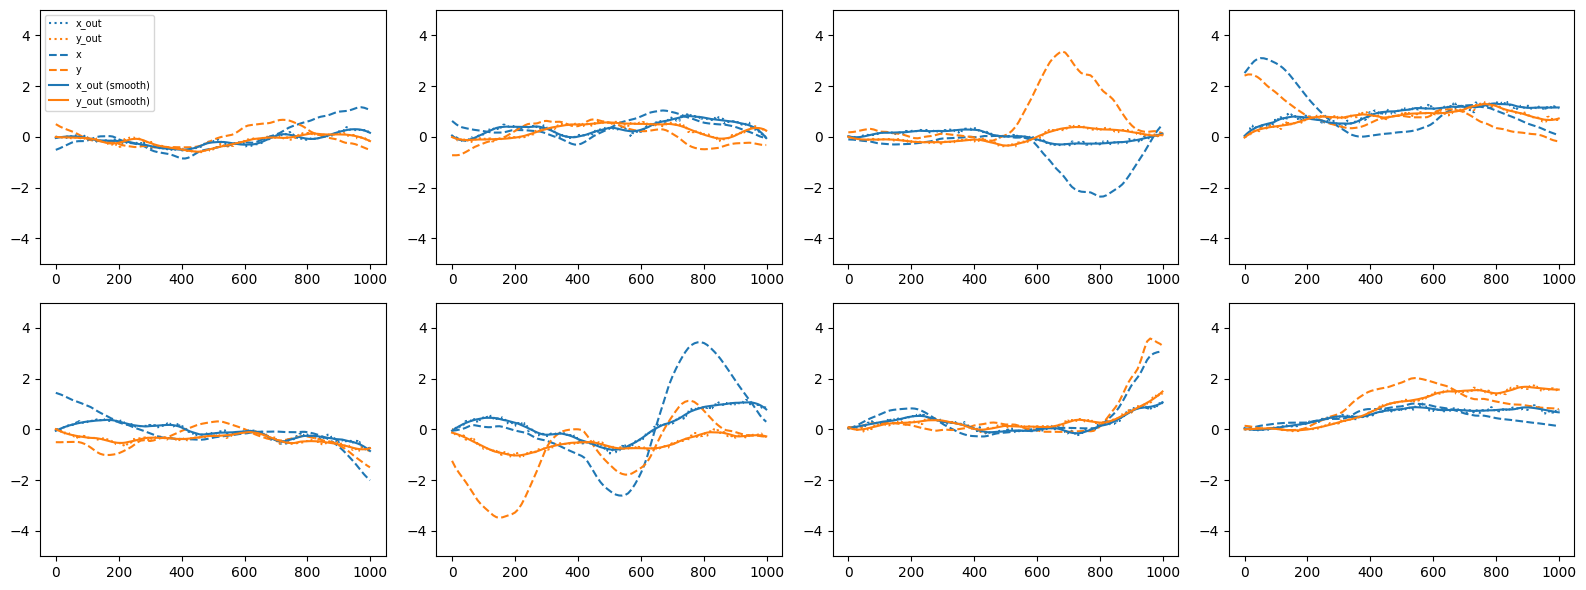

In [15]:
# network with no hidden layer - the 52 input spike trains connect directly to 2 non-spiking output neurons
# w_normal=(0, 0.02) gives untrained outputs of roughly +/-2, the same range as the whitened velocities
torch.manual_seed(42)
net = SNN([
    SNNLayer(num_neurons, 2, spiking=False, tau_range=(200*ms, 1000*ms), w_normal=(0.0, 0.02)),
], model_name='single_layer.pt')

# Training parameters
lr = 0.001 # learning rate
num_epochs = 10
max_num_batches = 40
length = 1
batch_size = 32 # small batches worked better for me for some reason

# Optimiser: net.parameters() gives every trainable w and tau in the network
optimizer = torch.optim.Adam(net.parameters(), lr=lr)

# training
loss_hist = []
val_loss_hist = []
with tqdm(total=num_epochs*max_num_batches) as pbar:
  last_epoch_loss = val_loss = null_val_loss = None
  for epoch in range(num_epochs):
    local_loss = []
    for x, y in batched_data(training_range, length=length, batch_size=batch_size, max_num_batches=max_num_batches):
      # Run the network
      y_out = net(x)
      # Compute a loss
      loss = mse(y_out, y)
      local_loss.append(loss.item())
      # Update gradients
      optimizer.zero_grad()
      loss.backward()
      optimizer.step()
      # keep every time constant at least 1 ms so exp(-dt/tau) stays a valid decay factor
      with torch.no_grad():
        for layer in net.layers:
          layer.tau.clamp_(min=1*ms)
      pbar.update(1)
      pbar.set_postfix(epoch=epoch, last_epoch_loss=last_epoch_loss, loss=loss.item(), val_loss=val_loss, null_val_loss=null_val_loss)
    last_epoch_loss = np.mean(local_loss)
    # validation loss on data the network never trains on
    val_loss, null_val_loss = evaluate_network(net, validation_range, length=length, batch_size=batch_size)
    pbar.set_postfix(epoch=epoch, last_epoch_loss=last_epoch_loss, loss=loss.item(), val_loss=val_loss, null_val_loss=null_val_loss)
    loss_hist.append(last_epoch_loss)
    val_loss_hist.append(val_loss)

# save the trained weights so Task 6 can reload them without retraining
torch.save(net.state_dict(), 'single_layer.pt')

# Plot the loss function over time
plt.figure()
plt.semilogy(loss_hist, label='Training loss')
plt.semilogy(val_loss_hist, label='Validation loss')
plt.axhline(null_val_loss, ls='--', c='r', label='Null model loss')
plt.xlabel('Epoch')
plt.ylabel('MSE')
plt.legend(loc='best')
plt.tight_layout()
plt.show()

testing_loss, null_testing_loss = evaluate_network(net, testing_range, length=length, batch_size=batch_size)
print(f"{testing_loss=}, {null_testing_loss=}")

# Task 5.4: plot trained output against the data for 8 random test windows
plt.figure(figsize=(16, 6))
with torch.no_grad():
  for x, y in batched_data(testing_range, length=length, batch_size=8, max_num_batches=1):
    y_out = net(x) # run the batch once, not once per subplot
    for b in range(8):
      plt.subplot(2, 4, b+1)
      plt.plot(y_out[b, 0, :], ':C0', label='x_out')
      plt.plot(y_out[b, 1, :], ':C1', label='y_out')
      plt.plot(y[b, 0, :], '--C0', label='x')
      plt.plot(y[b, 1, :], '--C1', label='y')
      # Plot a smoothed version as well
      plt.plot(savgol_filter(y_out[b, 0, :], 151, 3), '-C0', label='x_out (smooth)')
      plt.plot(savgol_filter(y_out[b, 1, :], 151, 3), '-C1', label='y_out (smooth)')
      plt.ylim(-5, 5)
      if b == 0:
        plt.legend(loc='best', fontsize=7)
plt.tight_layout()
plt.show()

## Task 6: Longer length decoding

Your code above probably doesn't look great when plotted. That's partly because the outputs start at 0 but the data doesn't necessarily have to, so it takes a while for them to get in sync, and partly because on some intervals it will just do badly. To fix this, and to extend the fit to a longer range of data, in this task we only use the final timestep of each segment and compare to the data. Take a 15 second segment of testing data, and sample every 0.2 seconds to get 75 data points. For each data point, take a 1 second segment of time before this data point (these will be overlapping), run your simulation for that one second, and use the final time point of the simulated output as your prediction. Plot this compared to the real data for 8 different segments of 15 seconds.

This should look like a reasonable fit to the data. Congratulations, you have used raw spiking output of neurons recorded from a monkey's brain to predict what it was doing on a computer screen it was interacting with. That's a brain machine interface right here.

1. ⚠️ Implement the decoding plot and run it on your trained network.

You can use the template below to get you started.

Your results might look something like this:

![Fits](fits.png)

In [16]:
# def decoding_plot(net, dt_decoding=0.2, decoding_start=1000, decoding_length=15, length=1, dt=1e-3, figdims=(4, 2)):
#     w_intervals = np.arange(decoding_start+length, decoding_start+length+decoding_length, dt_decoding)
#     batch_size_single = len(w_intervals)-1
#     num_time_points = int(np.round(length/dt))
#     nfx, nfy = figdims
#     nf = nfx*nfy
#     batch_size = nf*batch_size_single
#     nrows = nfy*2
#     ncols = nfx
#     with torch.no_grad():
#         x = torch.zeros((batch_size, num_neurons, num_time_points))
#         y = torch.zeros((batch_size, 2, num_time_points))
#         T = []
#         for b in range(batch_size):
#            w_start = decoding_start+dt_decoding*b
#            w_end = w_start+length
#            T.append(w_end)
#            # ... (copy data to x, y)
#         T = np.array(T)
#         y_out = ...
#         mean_mse = mse(y, y_out)
#         plt.figure(figsize=(ncols*3, nrows*2))
#         for nf_i in range(nf):
#             sp_x = nf_i % nfx
#             sp_y = nf_i // nfx
#             for i in range(2):
#                 plt.subplot(nrows, ncols, sp_x+1+2*ncols*sp_y+i*ncols)
#                 # ...
#                 plt.ylim(-4, 4)
#                 if sp_x==0:
#                     plt.ylabel('Velocity')
#                 if 2*sp_y+i==nrows-1:
#                     plt.xlabel('Time (s)')
#                 if nf_i==0:
#                     plt.legend(loc='best')
#         plt.suptitle(f'{net.fname}: {mean_mse=:.3f}')
#         plt.tight_layout()

# decoding_plot(models['single_layer.pt'])

## Task 7: Comparing spiking and non-spiking

1. ⚠️ Now try training your network with at least one spiking hidden layer. Compare your results to the non-spiking version. Note that training times with a spiking hidden layer are likely to be much longer. My training time went up from 2 minutes to 30 minutes (with CPU only).
2. ⚠️ Plot the trained distribution of weights and time constants for both models.

You might find it interesting to compare the distribution of time constants you find for the spiking hidden layer with the results in our paper [Perez et al. 2021](https://neural-reckoning.org/pub_heterogeneity.html). Note: this is not required for credit, only for your interest.

Well done - you have made it to the end!